<font size="6">Tutorial 2 — Calibrating the richness–mass relation by recycling weak-lensing posteriors</font>

<em>SBI edition.</em> Same science as the MCMC version: the same mass–observable relation, the same richness-binned selection, the same Eddington bias, and the same three attempts at fixing it. What changes is where the per-cluster weak-lensing posteriors come from.

In `mcmc_tutorial2_pymc.ipynb`, `wl_samples` was *asserted* — one line of Gaussian noise standing in for "whatever the WL pipeline gave us". Here we actually **build** it: an NFW surface-density profile, noisy shear data, and an amortized **neural posterior estimator (NPE)** trained once and evaluated on all 125 clusters at a stroke. The payoff is not just realism:

<ul>
    <li><strong>The flat prior stops being an abstraction.</strong> Attempt 2 fails because the stored posteriors carry the WL pipeline's flat prior on mass. In the MCMC version you had to take that on faith. Here it is a line of code you can point at — <code>BoxUniform(-2, 2)</code> — and the fix is to change it.</li>
    <li><strong>Nuisance parameters are free.</strong> Each cluster's profile depends on its concentration as well as its mass. We draw $c$ <em>inside</em> the simulator, and NPE marginalizes over it automatically — no extra sampled dimension, no integral.</li>
    <li><strong>The forward model can be anything.</strong> We call <code>colossus</code> directly. It is not differentiable and we never write down its likelihood; SBI only ever needs to <em>run</em> it.</li>
</ul>

The hierarchical layer (§6–§8) is **unchanged from the MCMC version** — `pm.Potential` with a hand-written recycling likelihood, sampled with NUTS. It only ever needed an array of per-cluster samples and does not care how they were made. §9 is new, and is the one thing the MCMC version could not have done.

<font size='5'>1. Setup</font>

Two families of import now. `pymc` / `pytensor.tensor` still drive the hierarchical fit — the recycling likelihood is non-standard and enters through `pm.Potential`, exactly as before. `torch` / `sbi` are new and are used only in §4 and §9, to train the networks that produce the per-cluster posteriors.

`quiet()` suppresses `sbi`'s live epoch counter so the notebook stays readable. Both the numpy and torch seeds are fixed.

<em>One environment note.</em> This stack pairs a NumPy-2 runtime with a torch built against NumPy 1.x, so `torch.as_tensor(ndarray)` and `.numpy()` raise `RuntimeError: Numpy is not available`. Every conversion below therefore goes through Python lists (`torch.tensor(arr.tolist())` / `np.array(t.tolist())`), the same workaround used in `sbi_tutorial_pymc.ipynb`. It is a packaging wart, not physics — if your environment is consistent you can use the direct calls.

In [1]:
import contextlib
import io
import time
import warnings
from math import erf

import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt
import torch
import sbi
from sbi.inference import NPE
from sbi.utils import BoxUniform
from colossus.cosmology import cosmology
from colossus.halo import profile_nfw

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"font.size": 12, "figure.figsize": (6, 4)})
np.random.seed(2807)
torch.manual_seed(2807)
rng = np.random.default_rng(2807)          # used by the simulator
cosmology.setCosmology("planck18")


@contextlib.contextmanager
def quiet():
    '''sbi's trainer prints a live epoch counter; hide it so the notebook stays readable.'''
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf), contextlib.redirect_stderr(buf):
        yield


def to_torch(arr):
    '''numpy -> torch without touching the NumPy C-API (see the note above).'''
    return torch.tensor(np.asarray(arr).tolist(), dtype=torch.float32)


def to_numpy(t):
    '''torch -> numpy, same reason.'''
    return np.array(t.tolist(), dtype=float)


print("pymc", pm.__version__, "| numpy", np.__version__,
      "| torch", torch.__version__, "| sbi", sbi.__version__)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/aidanbehmer/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/aidanbehmer/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/aidanbehmer/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 711, in start
    self.io_loop.start()
  

pymc 5.28.5 | numpy 2.4.6 | torch 2.0.1 | sbi 0.26.1



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/aidanbehmer/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/Users/aidanbehmer/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/Users/aidanbehmer/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 711, in start
    self.io_loop.start()
  

<font size='5'>2. Ground truth for the richness–mass relation</font>

Unchanged from the MCMC version. Fixes the three hyper-parameters we will try to recover, at values close to the DES-calibrated Murata et al. (2018) results: normalization $A=3.20$, mass slope $B=1.00$, intrinsic scatter $\sigma=0.35$.

The point worth emphasizing (and flagged in the comment) is that **&sigma; is intrinsic scatter, not measurement error**. It is a property of the cluster population — two halos of identical mass genuinely have different richnesses — so it does *not* shrink as the survey improves. Richness measurement error exists too but is small (~0.05–0.1 dex) and is ignored here to keep the model clean.

In [2]:
# TRUE scaling-relation parameters (our ground truth), near the Murata et al. 2018 values:
# NOTE: `sigma_true` is the INTRINSIC scatter sigma_{ln lambda | M} (a property of nature, ~0.25-0.46
# in Murata 2018) -- NOT a richness MEASUREMENT error. Real lambda also has measurement uncertainty
# ~0.05-0.1 dex (small compared to the intrinsic scatter and ignored here for clarity).
A_true, B_true, sigma_true = 3.20, 1.00, 0.35      # normalization, mass slope, intrinsic scatter (lognormal)
print("TRUE hyper-parameters:  A=%.2f  B=%.2f  sigma_intr=%.2f" % (A_true, B_true, sigma_true))

TRUE hyper-parameters:  A=3.20  B=1.00  sigma_intr=0.35


<font size='5'>3. Building the mock cluster sample (the generative model + the selection)</font>

Unchanged from the MCMC version. This is where the Eddington bias is *created*, so it is the most important cell to read carefully. Three steps:

<ul>
    <li><strong>Step 1 — richness bins.</strong> Clusters are selected in bins of richness &lambda; (20–30, 30–45, 45–65), mimicking DES Y1 redMaPPer. Counts fall steeply with richness (60/40/25) because the mass function does.</li>
    <li><strong>Step 2 — the per-bin mass distribution.</strong> Given a richness bin, the mass distribution is <em>not</em> the inverted MOR; it is
    $$p(M \mid \mathrm{bin}) \propto \frac{dn}{dM}\times P(\lambda \in \mathrm{bin} \mid M)$$
    i.e. the halo mass function ($dn/dM \propto M^{-\alpha}$, $\alpha=1.9$) times the selection probability. <code>mass_pdf_in_bin</code> evaluates this on a log-mass grid, with the selection term as a difference of error functions (the lognormal MOR integrated across the bin edges), and normalizes it.</li>
    <li><strong>Step 3 — draw the clusters.</strong> For each bin: sample masses from $p(M\mid\mathrm{bin})$, then draw a concentration from a Diemer-like $c(M)$ trend with 0.15 scatter, then draw the cluster's own richness from the MOR.</li>
</ul>

One line now carries more weight than it did before. In the MCMC version `c_true` was drawn and then never used — the comment said "carried along for later use". In this notebook it is used: §4's weak-lensing profile depends on concentration as well as mass, so each cluster's $c_j$ shapes the data we actually observe, and the inference has to marginalize it away.

The left panel plots $p(M\mid\mathrm{bin})$ for each bin — this is the object that drives the bias. Each is **skewed toward low mass**, because the mass function is falling steeply: within any richness bin, most clusters are low-mass ones that scattered up. The right panel shows the resulting sample against the true relation.

drew 125 clusters in 3 richness bins: {'20-30': 60, '30-45': 40, '45-65': 25}


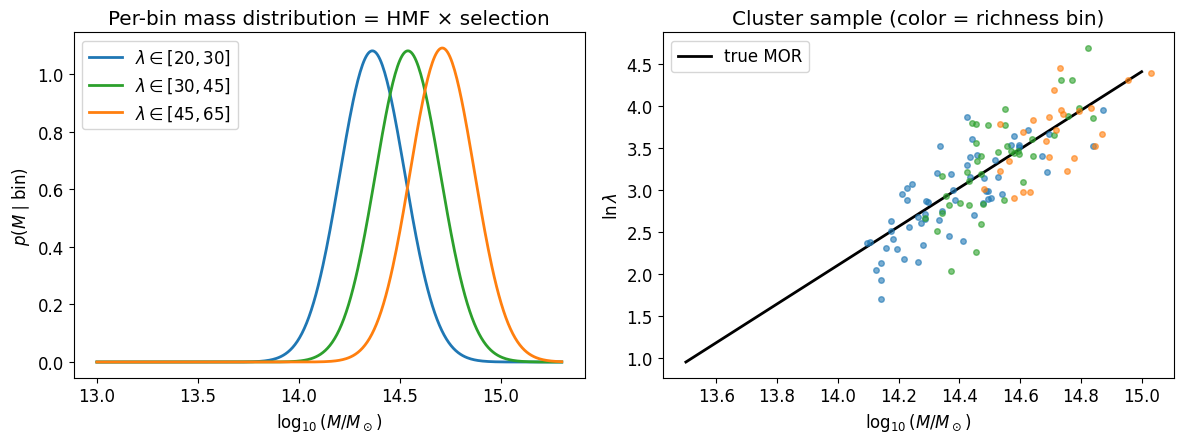

In [3]:
# --- Step 1: define richness bins (similar to DES Y1 redMaPPer) ---
bins = [(20, 30), (30, 45), (45, 65)]
n_per_bin = [60, 40, 25]                                  # cluster counts per bin (steeply falling)

# --- Step 2: posterior on M inside one bin: p(M | bin) ∝ dn/dM × P(lambda in bin | M) ---
alpha_mf = 1.9                                            # dn/dM ∝ M^-alpha (rough Tinker slope at cluster scales)
def mass_pdf_in_bin(lam_lo, lam_hi, n_grid=400):
    lnM = np.linspace(np.log(1e13), np.log(2e15), n_grid)
    mean_lnl = A_true + B_true*(lnM - np.log(3e14))                          # <ln lambda | M> on grid
    z_hi = (np.log(lam_hi) - mean_lnl) / (sigma_true*np.sqrt(2))
    z_lo = (np.log(lam_lo) - mean_lnl) / (sigma_true*np.sqrt(2))
    P_in_bin = 0.5*(np.vectorize(erf)(z_hi) - np.vectorize(erf)(z_lo))       # P(lambda in bin | M)
    pdf = P_in_bin * np.exp(-alpha_mf*(lnM - np.log(3e14)))                   # × mass function (M^-alpha factor; M dM absorbed)
    return lnM, pdf/np.trapezoid(pdf, lnM)

# --- Step 3: draw each cluster: mass from the bin's p(M|bin), then concentration from the M-c relation ---
sigma_mc = 0.15                                           # scatter in concentration at fixed mass (Murata-ish)
M_pop, c_pop, bin_idx, lam_pop = [], [], [], []
for b, (lam_lo, lam_hi) in enumerate(bins):
    lnM, pdf = mass_pdf_in_bin(lam_lo, lam_hi)
    lnM_j = np.random.choice(lnM, size=n_per_bin[b], p=pdf/pdf.sum())        # mass draws
    c_mean = 5.0 - 0.3*(lnM_j - np.log(3e14))                                 # c(M) ~ Diemer18-ish trend
    c_j    = c_mean + sigma_mc*np.random.randn(n_per_bin[b])
    # the cluster's own richness (draws ln lambda from the MOR, then takes exp)
    lam_j = np.exp(A_true + B_true*(lnM_j - np.log(3e14)) + sigma_true*np.random.randn(n_per_bin[b]))
    M_pop.append(np.exp(lnM_j)); c_pop.append(c_j); lam_pop.append(lam_j); bin_idx.append(np.full(n_per_bin[b], b))
M_true   = np.concatenate(M_pop);   c_true   = np.concatenate(c_pop)
lam_true = np.concatenate(lam_pop); bin_idx  = np.concatenate(bin_idx)
n_clusters = len(M_true)
print("drew", n_clusters, "clusters in", len(bins), "richness bins:", dict(zip([f"{l[0]}-{l[1]}" for l in bins], n_per_bin)))

# show the per-bin mass distribution (the Eddington-bias-relevant object)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
colors = ["tab:blue", "tab:green", "tab:orange"]
for b, (lam_lo, lam_hi) in enumerate(bins):
    lnM, pdf = mass_pdf_in_bin(lam_lo, lam_hi)
    ax[0].plot(lnM/np.log(10), pdf, color=colors[b], lw=2, label=fr"$\lambda\in[{lam_lo},{lam_hi}]$")
    sel = bin_idx == b
    ax[1].errorbar(np.log10(M_true[sel]), np.log(lam_true[sel]), fmt="o", ms=4, color=colors[b], alpha=0.6)
ax[0].set_xlabel(r"$\log_{10}(M/M_\odot)$"); ax[0].set_ylabel(r"$p(M\mid\mathrm{bin})$"); ax[0].set_title("Per-bin mass distribution = HMF × selection"); ax[0].legend()
gridM = np.linspace(13.5, 15.0, 50); ax[1].plot(gridM, A_true + B_true*(gridM*np.log(10)-np.log(3e14)), "k-", lw=2, label="true MOR")
ax[1].set_xlabel(r"$\log_{10}(M/M_\odot)$"); ax[1].set_ylabel(r"$\ln\lambda$"); ax[1].set_title("Cluster sample (color = richness bin)"); ax[1].legend()
plt.tight_layout(); plt.show()

<font size='5'>4. The weak-lensing forward model</font>

Now we forget the true masses and model what a survey actually measures.

Each cluster's latent variable is $x = \ln(M/M_{\rm piv})$ — the direct analogue of the per-cluster parameter "$a$" from Tutorial 1. In the MCMC version the WL measurement of it was a single line,

```python
wl_samples = x_wl[:, None] + sigma_WL*np.random.randn(n_clusters, n_samples)   # asserted
```

which quietly assumed the answer: that the posterior is Gaussian, unbiased, and of known width. Here we replace that assertion with a **forward model**. A cluster of mass $M$ and concentration $c$ has an NFW surface-density profile $\Sigma(r)$; we measure it in 10 radial bins from 200 to 2000 kpc/$h$ with per-bin noise of 0.45 dex (per-cluster WL is genuinely this noisy — the signal-to-noise on an individual cluster is only a few).

Two things to notice about `wl_simulator`:

<ul>
    <li><strong>Concentration is drawn inside it.</strong> $c$ is a nuisance parameter: it changes the data but we do not want to infer it. In a likelihood-based fit it would be an extra sampled dimension to marginalize over. In SBI you just sample it in the simulator and it is marginalized <em>by construction</em> — the network learns $p(x \mid d)$ with $c$ already integrated out. We use the same $c(M)$ relation and scatter that generated the real clusters in §3.</li>
    <li><strong>Nothing here is differentiable, and no likelihood is written down.</strong> It is a direct <code>colossus</code> call. The PyMC version of Tutorial 1 §6 had to rebuild the NFW profile as a <code>pytensor</code> graph — <code>pt.switch</code> branches, a differentiable <code>arctanh</code>, a loop over radii rebuilt as a tensor stack — purely so NUTS could get gradients. None of that is needed, and the same would be true of a full shear pipeline or a ray-tracing code.</li>
</ul>

The plot shows how the profile responds to mass (left) and what a single cluster's noisy data vector actually looks like (right).

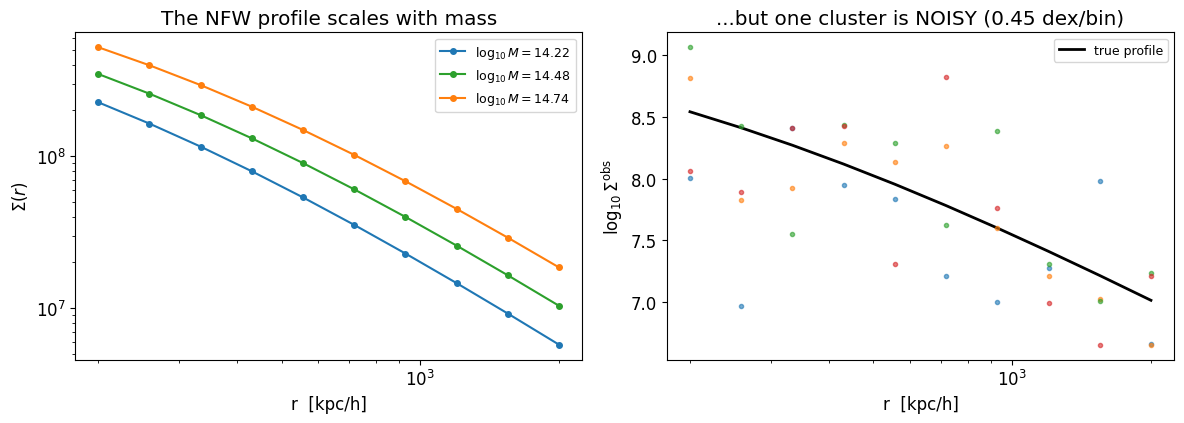

In [4]:
M_PIV   = 3e14
Z_LENS  = 0.3
wl_r    = np.logspace(np.log10(200.), np.log10(2000.), 10)   # 10 radial bins, kpc/h
shear_dex = 0.45                                             # per-bin 1-sigma noise in log10 Sigma


def wl_logSigma(x, c):
    '''The forward model: NFW surface density for a cluster at x = ln(M/M_piv), concentration c.
    Plain colossus -- not differentiable, no likelihood, which is all SBI ever needs.'''
    h = profile_nfw.NFWProfile(M=M_PIV*np.exp(x), c=c, z=Z_LENS, mdef="200m")
    return np.log10(h.surfaceDensity(wl_r))


def wl_simulator(x_arr):
    '''Vectorised simulator.  x_arr: (N,) -> (N, n_r) noisy log-profiles.
    The concentration is drawn HERE, so NPE marginalizes over it for free.'''
    x_arr = np.asarray(x_arr, dtype=float)
    c_arr = 5.0 - 0.3*x_arr + sigma_mc*rng.standard_normal(len(x_arr))    # same c(M) as section 3
    out = np.empty((len(x_arr), len(wl_r)), dtype=np.float32)
    for i, (xi, ci) in enumerate(zip(x_arr, c_arr)):
        out[i] = wl_logSigma(xi, max(ci, 0.5))                            # guard against c <= 0
    return out + shear_dex*rng.standard_normal(out.shape)


fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for x_demo, col in [(-0.6, "tab:blue"), (0.0, "tab:green"), (0.6, "tab:orange")]:
    ax[0].plot(wl_r, 10**wl_logSigma(x_demo, 5.0 - 0.3*x_demo), "-o", ms=4, color=col,
               label=r"$\log_{10}M=%.2f$" % np.log10(M_PIV*np.exp(x_demo)))
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("r  [kpc/h]"); ax[0].set_ylabel(r"$\Sigma(r)$")
ax[0].set_title("The NFW profile scales with mass"); ax[0].legend(fontsize=9)

ax[1].plot(wl_r, wl_logSigma(0.0, 5.0), "k-", lw=2, label="true profile")
for _ in range(4):
    ax[1].plot(wl_r, wl_simulator([0.0])[0], ".", alpha=0.6)
ax[1].set_xscale("log"); ax[1].set_xlabel("r  [kpc/h]"); ax[1].set_ylabel(r"$\log_{10}\Sigma^{\rm obs}$")
ax[1].set_title(f"...but one cluster is NOISY ({shear_dex} dex/bin)"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

<font size='4'>4.1 Training the amortized NPE — and choosing the prior on purpose</font>

The recipe is the one from Tutorial 1 §2.1: draw $x$ from a prior, push each draw through the simulator, and fit a conditional normalizing flow $q(x \mid d)$ to the resulting pairs. The flow never sees a likelihood; it only sees examples of "this mass produced this profile".

**Read the prior carefully, because it is the subject of this notebook.** We train on `BoxUniform(-2, 2)` — flat in $\ln M$ over a range that comfortably brackets the sample. That is a deliberate imitation of what a real WL pipeline does: it fits each cluster on its own, with no knowledge of the population it was drawn from, so its posteriors are flat-prior posteriors.

This is the hinge of the whole notebook. The stored samples carry that prior with them, and §6 shows that marginalizing over them *without* correcting for it leaves the Eddington bias completely intact. In the MCMC version that prior was an invisible assumption you had to be told about. Here it is a line of code — and §9 changes it.

Training is the one slow cell in the notebook (~1–2 min). It happens **once**: the network is amortized, so all 125 per-cluster posteriors in §4.2 come out of a single batched evaluation.

In [5]:
X_LO, X_HI = -2.0, 2.0
prior_flat = BoxUniform(low=torch.tensor([X_LO]), high=torch.tensor([X_HI]))   # THE WL PIPELINE'S FLAT PRIOR

N_SIM = 60_000

# ---- 1) SIMULATE -----------------------------------------------------------------
t0 = time.time()
theta_flat = prior_flat.sample((N_SIM,))                    # (N_SIM, 1)
x_sim      = to_numpy(theta_flat[:, 0])
d_sim      = to_torch(wl_simulator(x_sim))                  # (N_SIM, n_r)
print(f"simulated {N_SIM:,} cluster profiles in {time.time()-t0:.1f} s")

# ---- 2) TRAIN --------------------------------------------------------------------
print("training the amortized NPE (~1-2 min, done ONCE for all 125 clusters)...")
t0 = time.time()
inference_flat = NPE(prior=prior_flat, density_estimator="maf")
inference_flat.append_simulations(theta_flat, d_sim)
with quiet():
    npe_flat = inference_flat.build_posterior(
        inference_flat.train(training_batch_size=500, stop_after_epochs=20)
    )
print(f"   ...trained in {time.time()-t0:.0f} s")

simulated 60,000 cluster profiles in 1.6 s
training the amortized NPE (~1-2 min, done ONCE for all 125 clusters)...
   ...trained in 70 s


<font size='4'>4.2 The observations, and 125 posteriors from one network</font>

Now we generate what the survey actually sees — each cluster's noisy profile, built from its own true mass *and* its own true concentration from §3 — and condition the trained flow on all of them at once.

`wl_samples` has shape (n_clusters, 3000) and is **the only per-cluster input the rest of the notebook uses**. That is what "posterior recycling" means: Attempts 2, 3 and 4 re-use these stored samples instead of re-fitting shear profiles inside the hierarchical sampler. In a real survey this array is exactly what a WL pipeline hands you.

We also record `sigma_WL`, the mean posterior width. It is now a *measured* property of the inference rather than a number we chose. The shear noise was tuned so it lands near 0.37–0.40 — comfortably larger than the 0.35 intrinsic scatter, which is the regime where the Eddington bias is severe.

In [6]:
x_true = np.log(M_true / 3e14)          # the per-cluster latent (Tutorial 1's "a")
y_obs  = np.log(lam_true)               # the per-cluster richness

# the observed WL data: each cluster's own mass AND its own concentration from section 3
d_obs = np.array([wl_logSigma(x_true[j], c_true[j]) for j in range(n_clusters)])
d_obs = d_obs + shear_dex*rng.standard_normal(d_obs.shape)

# THE AMORTIZATION PAYOFF: 125 posteriors, one batched call, no retraining.
n_samples = 3000
t0 = time.time()
with quiet():
    s = npe_flat.sample_batched((n_samples,), x=to_torch(d_obs), show_progress_bars=False)
wl_samples = to_numpy(s.transpose(0, 1)[:, :, 0])        # (n_clusters, n_samples)
print(f"{n_clusters} per-cluster posteriors in {time.time()-t0:.1f} s")
print("wl_samples shape =", wl_samples.shape, " (clusters x posterior samples)")

x_wl     = wl_samples.mean(axis=1)                       # the WL point estimate
sigma_WL = wl_samples.std(axis=1).mean()                 # MEASURED, not assumed
print("mean NPE posterior width  sigma_WL = %.3f   (intrinsic scatter is %.2f)" % (sigma_WL, sigma_true))
print("residual scatter  std(x_wl - x_true) = %.3f,  mean offset = %+.3f"
      % ((x_wl - x_true).std(), (x_wl - x_true).mean()))

125 per-cluster posteriors in 0.7 s
wl_samples shape = (125, 3000)  (clusters x posterior samples)
mean NPE posterior width  sigma_WL = 0.379   (intrinsic scatter is 0.35)
residual scatter  std(x_wl - x_true) = 0.367,  mean offset = +0.012


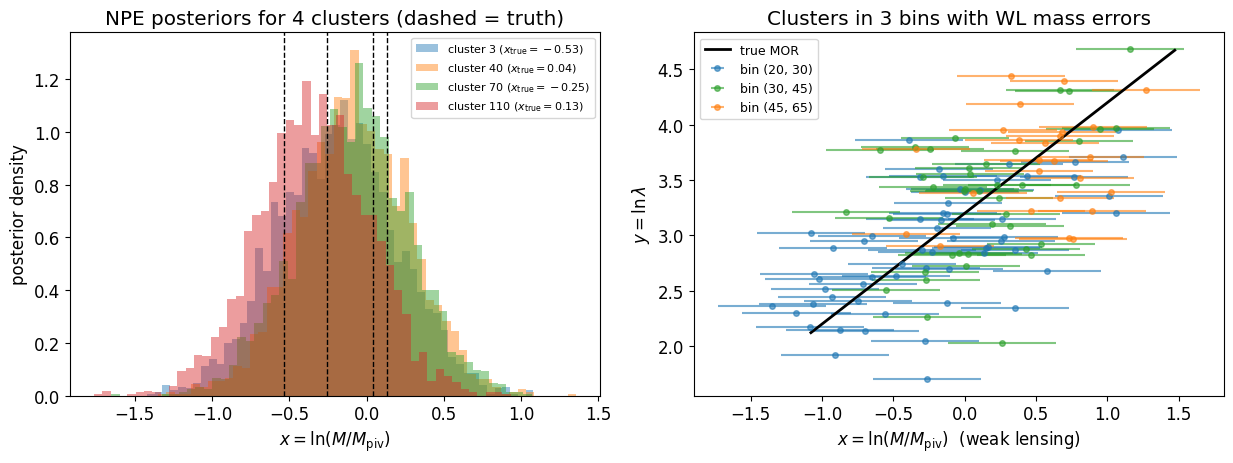

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8))

# LEFT: a few individual per-cluster posteriors -- the raw material we will RECYCLE
for j in [3, 40, 70, 110]:
    ax[0].hist(wl_samples[j], bins=50, density=True, alpha=0.45, label=r"cluster %d ($x_{\rm true}=%.2f$)" % (j, x_true[j]))
    ax[0].axvline(x_true[j], color="k", ls="--", lw=1)
ax[0].set_xlabel(r"$x=\ln(M/M_{\rm piv})$"); ax[0].set_ylabel("posterior density")
ax[0].set_title("NPE posteriors for 4 clusters (dashed = truth)"); ax[0].legend(fontsize=8)

# RIGHT: the whole sample -- this is the MCMC version's section 4 plot
grid = np.linspace(x_true.min()-0.2, x_true.max()+0.2, 50)
for b in range(len(bins)):
    sel = bin_idx == b
    ax[1].errorbar(x_wl[sel], y_obs[sel], xerr=sigma_WL, fmt="o", ms=4, alpha=0.6,
                   color=colors[b], label=f"bin {bins[b]}")
ax[1].plot(grid, A_true + B_true*grid, "k-", lw=2, label="true MOR")
ax[1].set_xlabel(r"$x=\ln(M/M_{\rm piv})$  (weak lensing)"); ax[1].set_ylabel(r"$y=\ln\lambda$")
ax[1].set_title("Clusters in 3 bins with WL mass errors"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

<font size='5'>5. Attempt 1 — naive OLS (and why it fails)</font>

The obvious thing to do: least-squares fit $\ln\lambda$ against the WL mass point estimates, ignoring the fact that the x-axis has errors.

This is classic **regression dilution / attenuation**. Noise on the independent variable spreads the points horizontally without changing their vertical positions, so the fitted slope is pulled toward zero by roughly

$$\hat{B} \approx B\,\frac{\sigma_{\rm mass}^2}{\sigma_{\rm mass}^2+\sigma_{\rm WL}^2}$$

The cell computes that expected attenuation factor and prints it next to the fitted slope so you can check the prediction. It also defines `sigma_mass` — the realized spread of true log-masses in this sample — which stands in for the width of the mass function and is re-used as the population prior in Attempts 3 and 4.

The red dashed line in the plot is visibly shallower than the black truth.

Attempt 1 (naive OLS):  A=3.16  B=0.61  sigma=0.468
expected attenuated slope = B*0.61 = 0.61   (true B=1.00)


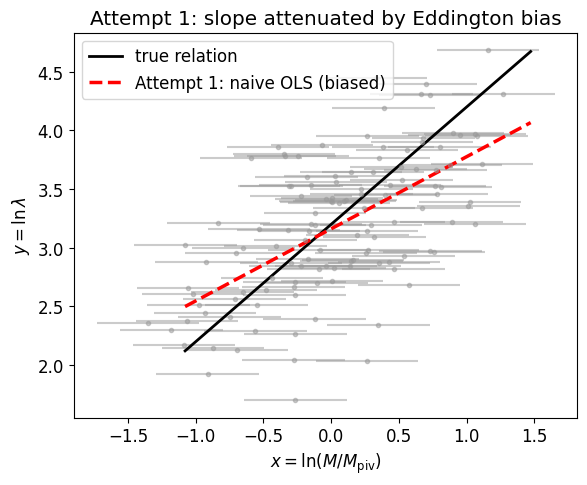

In [8]:
B_naive, A_naive = np.polyfit(x_wl, y_obs, 1)
sigma_naive = (y_obs - (A_naive + B_naive*x_wl)).std()
sigma_mass_eff = x_true.std()                            # the *realized* spread of true log-masses in this sample
attn = sigma_mass_eff**2 / (sigma_mass_eff**2 + sigma_WL**2)
print("Attempt 1 (naive OLS):  A=%.2f  B=%.2f  sigma=%.3f" % (A_naive, B_naive, sigma_naive))
print("expected attenuated slope = B*%.2f = %.2f   (true B=%.2f)" % (attn, B_true*attn, B_true))
sigma_mass = sigma_mass_eff                              # what later cells call sigma_mass

plt.figure(figsize=(6.5, 5))
plt.errorbar(x_wl, y_obs, xerr=sigma_WL, fmt="o", ms=3, color="0.6", alpha=0.5)
plt.plot(grid, A_true + B_true*grid, "k-", lw=2, label="true relation")
plt.plot(grid, A_naive + B_naive*grid, "r--", lw=2.5, label="Attempt 1: naive OLS (biased)")
plt.xlabel(r"$x=\ln(M/M_{\rm piv})$"); plt.ylabel(r"$y=\ln\lambda$")
plt.title("Attempt 1: slope attenuated by Eddington bias"); plt.legend(); plt.show()

<font size='5'>6. Attempt 2 — PyMC posterior recycling with a flat prior (still biased)</font>

The first real hierarchical fit, and **the code below is unchanged from the MCMC version**. That is the point: it consumes `wl_samples` and does not know or care that those samples came out of a neural network rather than a chain.

Instead of collapsing each cluster to a point estimate, we marginalize over its full WL posterior by Monte-Carlo averaging over the stored samples:

$$\mathcal{L}_j = \frac{1}{K}\sum_{k=1}^{K}\mathcal{N}\!\left(y_j \mid A + B\,x_{jk},\ \sigma\right),\qquad \ln\mathcal{L} = \sum_j \ln \mathcal{L}_j$$

**How this is coded in PyMC.** There is no built-in distribution for a Monte-Carlo-marginalized likelihood, so we build the log-likelihood as a tensor expression and hand it to `pm.Potential`, which simply adds it to the model's total log-probability. The steps are: broadcast $A + Bx$ over the (n_clusters &times; n_samples) sample array, form the per-sample log-Gaussian, then `pt.logsumexp(..., axis=1) - log(K)` to take the mean over samples *in log space* (avoiding underflow), then sum over clusters.

**Result: the slope is still wrong**, essentially matching Attempt 1. This is the pedagogical punchline of the notebook, and in this edition the cause is not an abstraction — it is `prior_flat`, four cells up. Recycling propagated the WL *uncertainty* correctly, but every sample in `wl_samples` was drawn under a flat prior on mass. Averaging under a flat prior asserts that all masses are equally likely a priori — which is badly false, since the mass function falls steeply — so the up-scattered low-mass clusters are never down-weighted.

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (1 chains in 1 job)
NUTS: [A, B, sigma]


Output()

Sampling 1 chain for 500 tune and 500 draw iterations (500 + 500 draws total) took 73 seconds.
Only one chain was sampled, this makes it impossible to run some convergence checks


Attempt 2 (PyMC recycle, FLAT prior):  A=3.17  B=0.62  sigma=0.409   <- same biased slope as Attempt 1


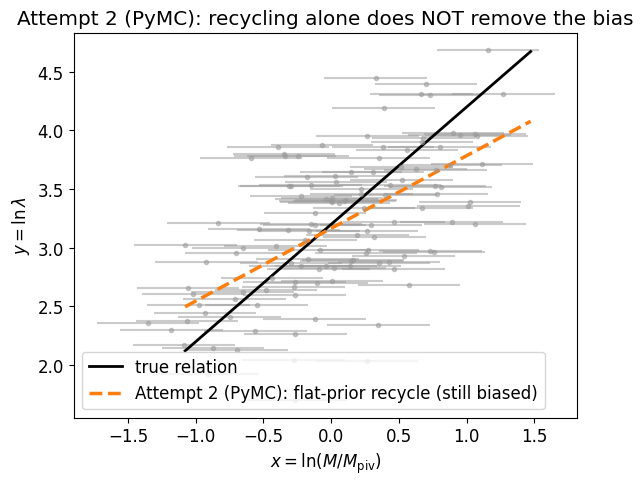

In [9]:
# --- Attempt 2 with PyMC: recycle the WL posterior samples, FLAT prior on sigma ---
# For each cluster j:
#     L_j = mean_k  N( y_obs[j] | A + B*wl_samples[j,k], sigma )
# i.e. we Monte-Carlo-marginalize over each cluster's WL posterior samples. There is no
# closed-form distribution for this, so we add log(sum_j L_j) directly as a custom pm.Potential.
# NOTE: this cell is byte-for-byte the hierarchical code from the MCMC tutorial. It only ever
# needed the `wl_samples` array -- the fact that a normalizing flow produced it is invisible here.
with pm.Model() as model_flat:
    A = pm.Flat("A", initval=A_true)
    B = pm.Flat("B", initval=B_true)
    sigma = pm.Uniform("sigma", 0.0, 3.0, initval=sigma_true)          # flat prior on sigma in (0, 3)

    mu = A + B * wl_samples                                            # (n_clusters, n_samples)
    logN = -0.5 * ((y_obs[:, None] - mu) / sigma) ** 2 - pt.log(sigma) # per-sample log-Gaussian (2*pi const dropped)
    loglike_j = pt.logsumexp(logN, axis=1) - np.log(n_samples)        # log of per-cluster mean over WL samples
    pm.Potential("recycle_ll", pt.sum(loglike_j))                     # total marginal log-likelihood

    idata_flat = pm.sample(500, tune=500, chains=1, target_accept=0.9,
                           random_seed=2807, progressbar=True)

A_f = idata_flat.posterior["A"].values.ravel()
B_f = idata_flat.posterior["B"].values.ravel()
s_f = idata_flat.posterior["sigma"].values.ravel()
print("Attempt 2 (PyMC recycle, FLAT prior):  A=%.2f  B=%.2f  sigma=%.3f   <- same biased slope as Attempt 1"
      % (A_f.mean(), B_f.mean(), s_f.mean()))

plt.figure(figsize=(6.5, 5))
plt.errorbar(x_wl, y_obs, xerr=sigma_WL, fmt="o", ms=3, color="0.6", alpha=0.5)
plt.plot(grid, A_true + B_true*grid, "k-", lw=2, label="true relation")
plt.plot(grid, A_f.mean() + B_f.mean()*grid, "--", color="tab:orange", lw=2.5, label="Attempt 2 (PyMC): flat-prior recycle (still biased)")
plt.xlabel(r"$x=\ln(M/M_{\rm piv})$"); plt.ylabel(r"$y=\ln\lambda$")
plt.title("Attempt 2 (PyMC): recycling alone does NOT remove the bias"); plt.legend(); plt.show()

<font size='5'>7. Attempt 3 — recycling + the mass-function weight (the fix)</font>

Identical model to Attempt 2 with **one extra line**: each WL sample is re-weighted by the population prior on mass before averaging,

$$\mathcal{L}_j = \frac{1}{K}\sum_k \mathcal{N}\!\left(y_j \mid A+B\,x_{jk},\ \sigma\right)\,p(x_{jk}),\qquad \ln p(x) = -\tfrac{1}{2}\left(x/\sigma_{\rm mass}\right)^2$$

This is **importance sampling**: samples were drawn under the WL pipeline's flat prior, and multiplying by $p(x)$ re-weights them to the prior we actually believe (a Gaussian stand-in for the falling mass function, width `sigma_mass`). In code it is `logW` added *inside* the `logsumexp` — inside matters, since the weight varies sample by sample; adding it outside would be a constant offset and would do nothing.

The effect is exactly the intuition behind Eddington bias: samples at low mass get up-weighted and samples at high mass get down-weighted, correcting the asymmetry that flattened the slope.

Sampling is a bit longer here (1000 draws) because we quote uncertainties. The fitted A, B, &sigma; are printed alongside the truth, and the green line in the plot now tracks the black one.

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (1 chains in 1 job)
NUTS: [A, B, sigma]


Output()

Sampling 1 chain for 500 tune and 1_000 draw iterations (500 + 1_000 draws total) took 124 seconds.
Only one chain was sampled, this makes it impossible to run some convergence checks


Attempt 3 (PyMC recycle + mass function):  A=3.17±0.04  B=1.00±0.12  sigma=0.369±0.049
                                            -> recovers truth (A=3.20, B=1.00, sigma=0.35)


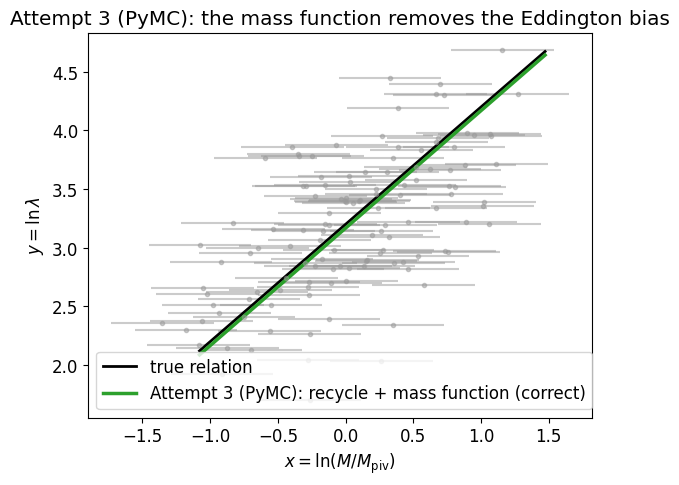

In [10]:
# --- Attempt 3 with PyMC: recycle WL samples + HALO MASS FUNCTION weight (removes Eddington bias) ---
# Identical to Attempt 2, except each WL sample is re-weighted by the mass function p(x) before averaging:
#     L_j = mean_k  N( y_obs[j] | A + B*wl_samples[j,k], sigma ) * exp(-0.5*(wl_samples[j,k]/sigma_mass)^2)
# In log-space the weight is just an additive term INSIDE the logsumexp (the correct importance-sampling fix).
with pm.Model() as model_massfunc:
    A = pm.Flat("A", initval=A_true)
    B = pm.Flat("B", initval=B_true)
    sigma = pm.Uniform("sigma", 0.0, 3.0, initval=sigma_true)          # flat prior on sigma in (0, 3)

    mu   = A + B * wl_samples                                          # (n_clusters, n_samples)
    logN = -0.5 * ((y_obs[:, None] - mu) / sigma) ** 2 - pt.log(sigma) # per-sample log-Gaussian likelihood
    logW = -0.5 * (wl_samples / sigma_mass) ** 2                       # log mass-function weight p(x) (the fix)
    loglike_j = pt.logsumexp(logN + logW, axis=1) - np.log(n_samples)  # log of per-cluster weighted mean
    pm.Potential("recycle_mf_ll", pt.sum(loglike_j))

    idata_mf = pm.sample(1000, tune=500, chains=1, target_accept=0.9,
                         random_seed=2807, progressbar=True)

A_m = idata_mf.posterior["A"].values.ravel()
B_m = idata_mf.posterior["B"].values.ravel()
s_m = idata_mf.posterior["sigma"].values.ravel()
print("Attempt 3 (PyMC recycle + mass function):  A=%.2f±%.2f  B=%.2f±%.2f  sigma=%.3f±%.3f"
      % (A_m.mean(), A_m.std(), B_m.mean(), B_m.std(), s_m.mean(), s_m.std()))
print("                                            -> recovers truth (A=%.2f, B=%.2f, sigma=%.2f)" % (A_true, B_true, sigma_true))

plt.figure(figsize=(6.5, 5))
plt.errorbar(x_wl, y_obs, xerr=sigma_WL, fmt="o", ms=3, color="0.6", alpha=0.5)
plt.plot(grid, A_true + B_true*grid, "k-", lw=2, label="true relation")
plt.plot(grid, A_m.mean() + B_m.mean()*grid, "-", color="tab:green", lw=2.5, label="Attempt 3 (PyMC): recycle + mass function (correct)")
plt.xlabel(r"$x=\ln(M/M_{\rm piv})$"); plt.ylabel(r"$y=\ln\lambda$")
plt.title("Attempt 3 (PyMC): the mass function removes the Eddington bias"); plt.legend(); plt.show()

<font size='5'>8. Side-by-side comparison and the hyper-posterior</font>

Collects the three attempts into one table against the truth, then plots the thing that actually matters for cosmology: the joint hyper-posterior in the (mass slope $B$, intrinsic scatter $\sigma_{\ln\lambda|M}$) plane.

Why this plane? Cluster cosmology is limited by exactly these two numbers — a biased slope or an underestimated scatter propagates straight into &sigma;<sub>8</sub> and &Omega;<sub>m</sub>. The scatter plot shows the flat-prior cloud (orange) and the mass-function-weighted cloud (green) against the truth (black star) and the naive point estimate (red x). Only the green cloud brackets the truth; the orange one is *confidently wrong* — tight error bars around a biased value, which is the worst failure mode in practice.

                              A       B       sigma_intr
truth                    :  3.20    1.00    0.350
Attempt 1 naive OLS      :  3.16    0.61    0.468   <- Eddington bias
Attempt 2 flat-recycle   :  3.17    0.62    0.409   <- still biased
Attempt 3 + mass function:  3.17    1.00    0.369   <- correct


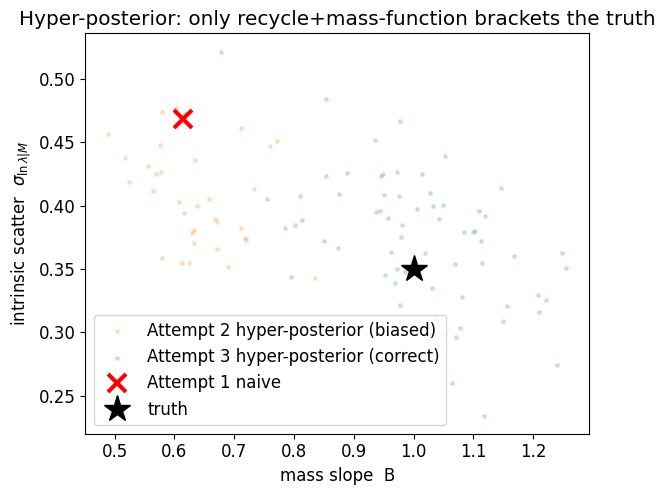

In [11]:
print("                              A       B       sigma_intr")
print("truth                    :  %.2f    %.2f    %.3f" % (A_true, B_true, sigma_true))
print("Attempt 1 naive OLS      :  %.2f    %.2f    %.3f   <- Eddington bias" % (A_naive, B_naive, sigma_naive))
print("Attempt 2 flat-recycle   :  %.2f    %.2f    %.3f   <- still biased" % (A_f.mean(), B_f.mean(), s_f.mean()))
print("Attempt 3 + mass function:  %.2f    %.2f    %.3f   <- correct" % (A_m.mean(), B_m.mean(), s_m.mean()))

# the hyper-posterior on (slope B, intrinsic scatter sigma): truth inside the correct one, not the biased one
plt.figure(figsize=(6.5, 5.2))
plt.scatter(B_f[::15], s_f[::15], s=6, alpha=0.2, color="tab:orange", label="Attempt 2 hyper-posterior (biased)")
plt.scatter(B_m[::15], s_m[::15], s=6, alpha=0.2, color="tab:green", label="Attempt 3 hyper-posterior (correct)")
plt.plot(B_naive, sigma_naive, "rx", ms=13, mew=3, label="Attempt 1 naive")
plt.plot(B_true, sigma_true, "k*", ms=20, label="truth")
plt.xlabel("mass slope  B"); plt.ylabel(r"intrinsic scatter  $\sigma_{\ln\lambda|M}$")
plt.title("Hyper-posterior: only recycle+mass-function brackets the truth"); plt.legend(); plt.show()

<font size='5'>9. Attempt 4 — put the mass function in the <em>simulator</em> (the SBI-native fix)</font>

<em>This section has no counterpart in the MCMC version.</em>

Attempt 3 fixed the bias by re-weighting samples that had been drawn under the wrong prior. That is the only option when all you have is a stored chain: you cannot change the prior a finished chain was run with, you can only correct for it afterwards.

With SBI you have a second option, because the prior is an input to training rather than a property of a finished run. **Retrain the network with the mass function as the prior**, and the posteriors come out already Eddington-corrected. Then recycle them with *no* weight at all — the Attempt 2 code, verbatim.

Why that is legitimate, in one line. Writing $L_j(x)$ for the WL likelihood of cluster $j$ and $p_{\rm pop}$ for the mass function:

$$\underbrace{\frac{1}{K}\sum_k \mathcal{N}(y_j\mid A+Bx_k)\,p_{\rm pop}(x_k)}_{\text{Attempt 3},\ x_k\sim L_j}\;\propto\;\int\! \mathcal{N}\,L_j\,p_{\rm pop}\,dx \;\propto\; \underbrace{\frac{1}{K}\sum_k \mathcal{N}(y_j\mid A+Bx_k)}_{\text{Attempt 4},\ x_k\sim L_j p_{\rm pop}}$$

The two differ only by $\int L_j p_{\rm pop}\,dx$, which depends on the data $d_j$ but **not** on $(A,B,\sigma)$ — so it is a per-cluster constant and drops straight out of the hyper-posterior. Importance-reweighting the samples and changing the prior they were drawn from are the same operation, done at opposite ends of the pipeline.

This is the same move as Tutorial 1 §6, where simulating the stacking operation meant the $\sqrt{\pi/2}$ median correction never had to be derived — it fell out of the simulator. Here the correction that never has to be derived is the Eddington bias itself.

**Which should you actually use?** Attempt 3, usually. Its whole virtue is that it needs nothing but stored samples, so it works on an archival catalogue produced by someone else, and you can re-run it under a different mass function in seconds. Attempt 4 needs you to own the WL pipeline and to retrain per assumed population — which breaks amortization exactly where you want it, since the mass function depends on the cosmology you are trying to measure. The honest summary is that Attempt 3 is the practical tool and Attempt 4 is the proof that the bias is a statement about priors, not about estimators.

In [12]:
# --- Attempt 4: the SAME simulator, a DIFFERENT prior ---------------------------------
# The mass function now plays the role of the prior during training, instead of being
# applied as an importance weight afterwards.  (A Gaussian of width sigma_mass, exactly
# the p(x) that Attempt 3 used as `logW` -- so the two are directly comparable.)
from torch.distributions import Normal, Independent

prior_mf = Independent(Normal(torch.tensor([0.0]), torch.tensor([float(sigma_mass)])), 1)

theta_mf  = prior_mf.sample((N_SIM,))
x_sim_mf  = to_numpy(theta_mf[:, 0])
d_sim_mf  = to_torch(wl_simulator(x_sim_mf))        # <- the SAME simulator, untouched

print("retraining with the mass function as the prior (~1-2 min)...")
t0 = time.time()
inference_mf = NPE(prior=prior_mf, density_estimator="maf")
inference_mf.append_simulations(theta_mf, d_sim_mf)
with quiet():
    npe_mf = inference_mf.build_posterior(
        inference_mf.train(training_batch_size=500, stop_after_epochs=20)
    )
    s_mf = npe_mf.sample_batched((n_samples,), x=to_torch(d_obs), show_progress_bars=False)
wl_samples_mf = to_numpy(s_mf.transpose(0, 1)[:, :, 0])
print(f"   ...trained + evaluated on all {n_clusters} clusters in {time.time()-t0:.0f} s")
print("per-cluster posterior width:  flat prior %.3f  ->  mass-function prior %.3f"
      % (sigma_WL, wl_samples_mf.std(axis=1).mean()))

retraining with the mass function as the prior (~1-2 min)...
   ...trained + evaluated on all 125 clusters in 54 s
per-cluster posterior width:  flat prior 0.379  ->  mass-function prior 0.291


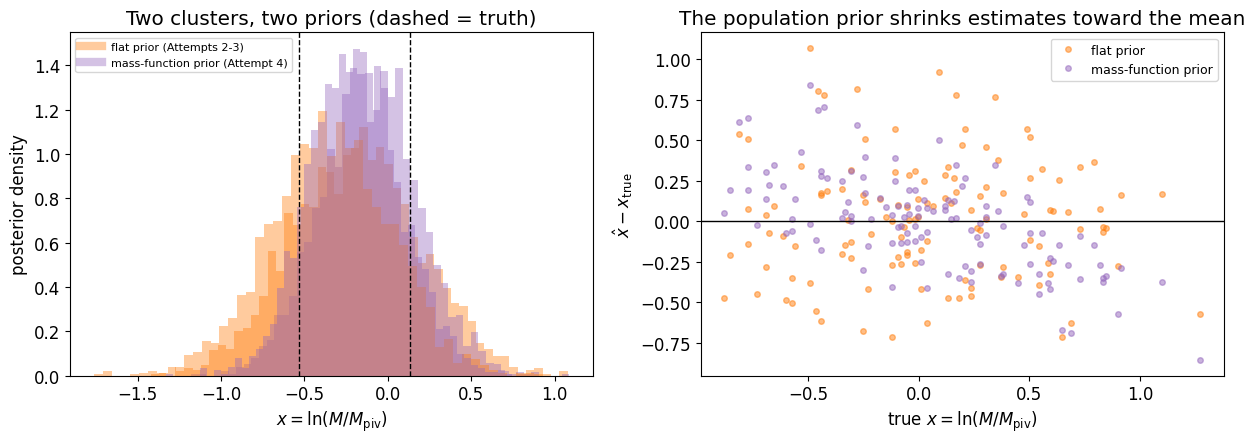

In [13]:
# What the prior swap did to the individual posteriors: they tighten, and they shift DOWN in mass
# (an up-scattered low-mass cluster is no longer allowed to sit at an a-priori-implausible mass).
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
for j in [3, 110]:
    ax[0].hist(wl_samples[j],    bins=50, density=True, alpha=0.4, color="tab:orange")
    ax[0].hist(wl_samples_mf[j], bins=50, density=True, alpha=0.4, color="tab:purple")
    ax[0].axvline(x_true[j], color="k", ls="--", lw=1)
ax[0].plot([], [], color="tab:orange", lw=6, alpha=0.4, label="flat prior (Attempts 2-3)")
ax[0].plot([], [], color="tab:purple", lw=6, alpha=0.4, label="mass-function prior (Attempt 4)")
ax[0].set_xlabel(r"$x=\ln(M/M_{\rm piv})$"); ax[0].set_ylabel("posterior density")
ax[0].set_title("Two clusters, two priors (dashed = truth)"); ax[0].legend(fontsize=8)

ax[1].plot(x_true, wl_samples.mean(axis=1)    - x_true, "o", ms=4, alpha=0.5, color="tab:orange", label="flat prior")
ax[1].plot(x_true, wl_samples_mf.mean(axis=1) - x_true, "o", ms=4, alpha=0.5, color="tab:purple", label="mass-function prior")
ax[1].axhline(0, color="k", lw=1)
ax[1].set_xlabel(r"true $x=\ln(M/M_{\rm piv})$"); ax[1].set_ylabel(r"$\hat{x} - x_{\rm true}$")
ax[1].set_title("The population prior shrinks estimates toward the mean"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

In [14]:
# --- Recycle the new samples with NO weight: this is the Attempt 2 model, unchanged ---
with pm.Model() as model_sbi_prior:
    A = pm.Flat("A", initval=A_true)
    B = pm.Flat("B", initval=B_true)
    sigma = pm.Uniform("sigma", 0.0, 3.0, initval=sigma_true)

    mu = A + B * wl_samples_mf                                         # (n_clusters, n_samples)
    logN = -0.5 * ((y_obs[:, None] - mu) / sigma) ** 2 - pt.log(sigma)
    loglike_j = pt.logsumexp(logN, axis=1) - np.log(n_samples)         # NO logW -- the prior is already in the samples
    pm.Potential("recycle_ll", pt.sum(loglike_j))

    idata_sbi = pm.sample(1000, tune=500, chains=1, target_accept=0.9,
                          random_seed=2807, progressbar=True)

A_s = idata_sbi.posterior["A"].values.ravel()
B_s = idata_sbi.posterior["B"].values.ravel()
s_s = idata_sbi.posterior["sigma"].values.ravel()
print("Attempt 4 (prior in the simulator):  A=%.2f±%.2f  B=%.2f±%.2f  sigma=%.3f±%.3f"
      % (A_s.mean(), A_s.std(), B_s.mean(), B_s.std(), s_s.mean(), s_s.std()))
print("Attempt 3 (importance weight)     :  A=%.2f±%.2f  B=%.2f±%.2f  sigma=%.3f±%.3f"
      % (A_m.mean(), A_m.std(), B_m.mean(), B_m.std(), s_m.mean(), s_m.std()))
print("   -> the same answer by two routes: re-weighting the samples, or changing the prior they came from.")

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (1 chains in 1 job)
NUTS: [A, B, sigma]


Output()

Sampling 1 chain for 500 tune and 1_000 draw iterations (500 + 1_000 draws total) took 111 seconds.
Only one chain was sampled, this makes it impossible to run some convergence checks


Attempt 4 (prior in the simulator):  A=3.16±0.04  B=1.02±0.12  sigma=0.377±0.049
Attempt 3 (importance weight)     :  A=3.17±0.04  B=1.00±0.12  sigma=0.369±0.049
   -> the same answer by two routes: re-weighting the samples, or changing the prior they came from.


                              A       B       sigma_intr
truth                    :  3.20    1.00    0.350
Attempt 1 naive OLS      :  3.16    0.61    0.468   <- Eddington bias
Attempt 2 flat-recycle   :  3.17    0.62    0.409   <- still biased
Attempt 3 + MF weight    :  3.17    1.00    0.369   <- correct (works on stored chains)
Attempt 4 MF in simulator:  3.16    1.02    0.377   <- correct (needs the pipeline)


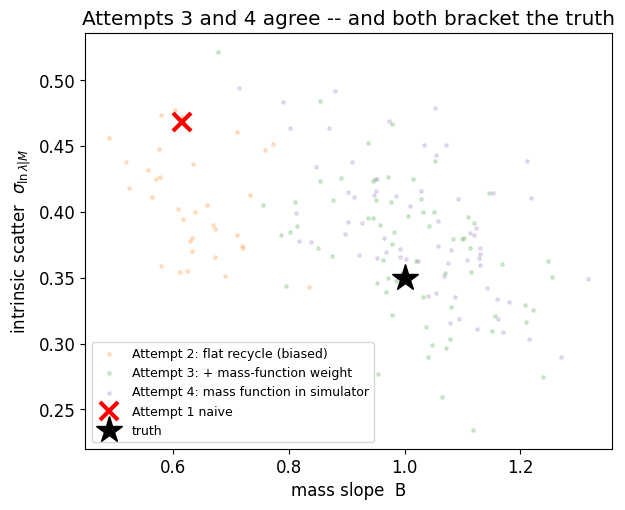

In [15]:
print("                              A       B       sigma_intr")
print("truth                    :  %.2f    %.2f    %.3f" % (A_true, B_true, sigma_true))
print("Attempt 1 naive OLS      :  %.2f    %.2f    %.3f   <- Eddington bias" % (A_naive, B_naive, sigma_naive))
print("Attempt 2 flat-recycle   :  %.2f    %.2f    %.3f   <- still biased" % (A_f.mean(), B_f.mean(), s_f.mean()))
print("Attempt 3 + MF weight    :  %.2f    %.2f    %.3f   <- correct (works on stored chains)" % (A_m.mean(), B_m.mean(), s_m.mean()))
print("Attempt 4 MF in simulator:  %.2f    %.2f    %.3f   <- correct (needs the pipeline)" % (A_s.mean(), B_s.mean(), s_s.mean()))

plt.figure(figsize=(6.8, 5.4))
plt.scatter(B_f[::15], s_f[::15], s=6, alpha=0.2, color="tab:orange", label="Attempt 2: flat recycle (biased)")
plt.scatter(B_m[::15], s_m[::15], s=6, alpha=0.2, color="tab:green",  label="Attempt 3: + mass-function weight")
plt.scatter(B_s[::15], s_s[::15], s=6, alpha=0.2, color="tab:purple", label="Attempt 4: mass function in simulator")
plt.plot(B_naive, sigma_naive, "rx", ms=13, mew=3, label="Attempt 1 naive")
plt.plot(B_true, sigma_true, "k*", ms=20, label="truth")
plt.xlabel("mass slope  B"); plt.ylabel(r"intrinsic scatter  $\sigma_{\ln\lambda|M}$")
plt.title("Attempts 3 and 4 agree -- and both bracket the truth"); plt.legend(fontsize=9); plt.show()

<font size='5'>10. Presentation figure</font>

Purely cosmetic — no new science. Re-draws the two key panels (the calibrated relation on the left, the (slope, scatter) hyper-posterior on the right) with larger fonts and saves a 220 dpi PNG to `slide_figures/richness_mass_calibration_sbi.png` for use in a talk. The `rc_context` block keeps the enlarged style local so the notebook's other plots are unaffected, and `os.makedirs(..., exist_ok=True)` creates the output directory if needed.

Note the filename differs from the MCMC version's so the two can sit side by side in a slide deck.

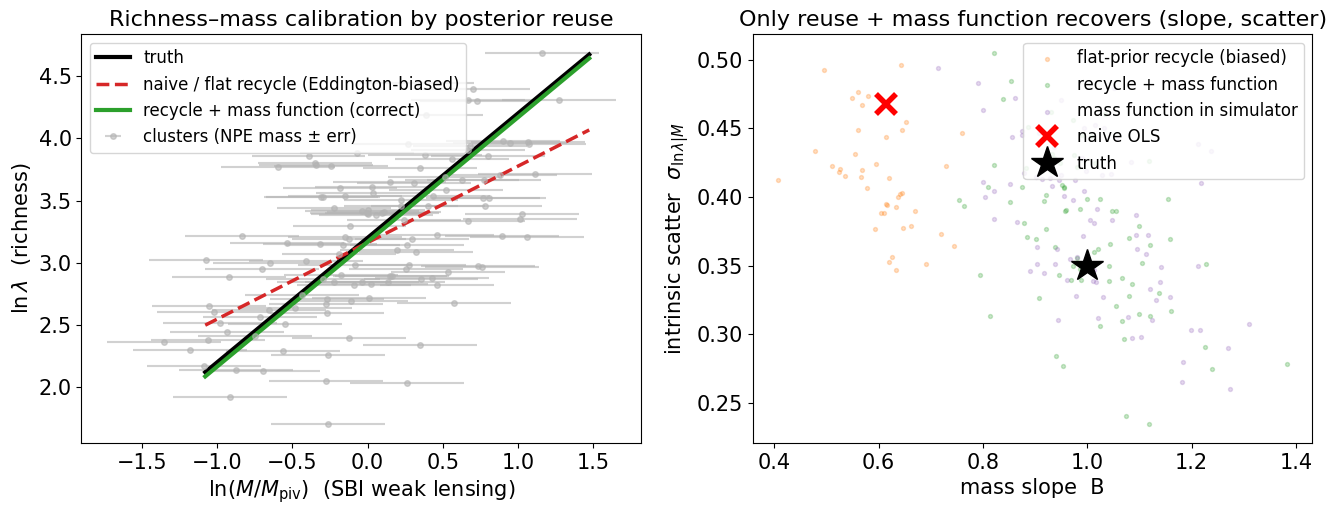

saved -> slide_figures/richness_mass_calibration_sbi.png


In [16]:
# --- polished figure for a PROJECT-PITCH SLIDE (saved high-res to slide_figures/) ---
import os; os.makedirs("slide_figures", exist_ok=True)
with plt.rc_context({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "legend.fontsize": 12,
                     "savefig.dpi": 220, "savefig.bbox": "tight"}):
    fig, ax = plt.subplots(1, 2, figsize=(13.5, 5.4))
    # LEFT: the relation -- data + true + biased + correct
    ax[0].errorbar(x_wl, y_obs, xerr=sigma_WL, fmt="o", ms=4, color="0.7", alpha=0.6, label="clusters (NPE mass ± err)")
    ax[0].plot(grid, A_true + B_true*grid, "k-", lw=3, label="truth")
    ax[0].plot(grid, A_naive + B_naive*grid, "--", color="tab:red", lw=2.5, label="naive / flat recycle (Eddington-biased)")
    ax[0].plot(grid, A_m.mean() + B_m.mean()*grid, "-", color="tab:green", lw=3, label="recycle + mass function (correct)")
    ax[0].set_xlabel(r"$\ln(M/M_{\rm piv})$  (SBI weak lensing)"); ax[0].set_ylabel(r"$\ln\lambda$  (richness)")
    ax[0].set_title("Richness–mass calibration by posterior reuse"); ax[0].legend(loc="upper left")
    # RIGHT: the (slope, scatter) hyper-posterior
    ax[1].scatter(B_f[::12], s_f[::12], s=8, alpha=0.25, color="tab:orange", label="flat-prior recycle (biased)")
    ax[1].scatter(B_m[::12], s_m[::12], s=8, alpha=0.25, color="tab:green", label="recycle + mass function")
    ax[1].scatter(B_s[::12], s_s[::12], s=8, alpha=0.25, color="tab:purple", label="mass function in simulator")
    ax[1].plot(B_naive, sigma_naive, "rx", ms=15, mew=4, label="naive OLS")
    ax[1].plot(B_true, sigma_true, "k*", ms=24, label="truth")
    ax[1].set_xlabel("mass slope  B"); ax[1].set_ylabel(r"intrinsic scatter  $\sigma_{\ln\lambda|M}$")
    ax[1].set_title("Only reuse + mass function recovers (slope, scatter)"); ax[1].legend(loc="upper right")
    fig.tight_layout(); fig.savefig("slide_figures/richness_mass_calibration_sbi.png"); plt.show()
print("saved -> slide_figures/richness_mass_calibration_sbi.png")

<font size='5'>11. Sanity check — the oracle fit</font>

The final diagnostic: refit by OLS using the **true** masses, which no real survey ever has. This "oracle" is the best any method could do given this particular realization of the sample, so it — not the input values $A=3.20$, $B=1.00$, $\sigma=0.35$ — is the fair target for Attempts 3 and 4. The gap between the oracle and the input truth is just finite-sample noise from drawing ~125 clusters.

Comparing the printed lines tells you how much of any residual offset is method bias versus sample noise. Some difference is expected, and in this edition there are three known approximations rather than two:

<ul>
    <li>the Gaussian <code>sigma_mass</code> weight is only a stand-in for the real falling mass function;</li>
    <li>the richness-bin selection is not modelled explicitly in the hierarchical likelihood;</li>
    <li>the NPE posteriors are themselves approximate — a trained flow is not an exact posterior, and at this noise level it is mildly under-dispersed (compare <code>sigma_WL</code> with the residual scatter printed in §4.2).</li>
</ul>

That third item is the price of simulation-based inference, and it is worth stating plainly rather than hiding: SBI buys you an arbitrary forward model and free nuisance marginalization, and charges you an approximation error that MCMC does not have. Here it is a few percent on the posterior width — far smaller than the factor-of-two slope bias this notebook is about, but not zero.

In [17]:
B_oracle, A_oracle = np.polyfit(x_true, y_obs, 1)
sigma_oracle = (y_obs - (A_oracle + B_oracle*x_true)).std()
print("oracle (true masses) :  A=%.3f  B=%.3f  sigma=%.3f" % (A_oracle, B_oracle, sigma_oracle))
print("Attempt 3            :  A=%.3f  B=%.3f  sigma=%.3f" % (A_m.mean(), B_m.mean(), s_m.mean()))
print("Attempt 4            :  A=%.3f  B=%.3f  sigma=%.3f" % (A_s.mean(), B_s.mean(), s_s.mean()))

oracle (true masses) :  A=3.154  B=1.027  sigma=0.347
Attempt 3            :  A=3.168  B=1.001  sigma=0.369
Attempt 4            :  A=3.162  B=1.023  sigma=0.377
